# 01 — LSTM anclada a TSMOM

> Pregunta: ¿puede una LSTM pequeña aprender ajustes económicamente útiles sobre una exposición TSMOM preexistente? Este cuaderno es educativo y exploratorio; no prueba alpha ni superioridad fuera de muestra.

La muestra se limita deliberadamente a retornos realizados entre 2018 y 2023: 2018–2022 para entrenamiento y 2023 para validación. No se consultan observaciones de 2024–2026.

## <b>Block 01 — Datos y baseline causal</b>

> La decisión fechada en $t$ usa únicamente precios y retornos disponibles al cierre de $t$; su exposición se aplica al retorno simple de la siguiente sesión, $R_{t+1}$.

El baseline es TSMOM long/cash de 126 sesiones, escalado por volatilidad EWMA con $\lambda=0.94$, objetivo anual de 12% y máximo 1×. La varianza EWMA se inicializa con 20 retornos y se actualiza con el retorno de $t$ para emitir el pronóstico de $t+1$. Esto es una simulación idealizada de retornos diarios: no representa órdenes, fills ni ejecución real.

In [1]:
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from torch import nn

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

START = pd.Timestamp('2018-01-02')
TRAIN_END = pd.Timestamp('2022-12-31')
VALIDATION_END = pd.Timestamp('2023-12-31')
MOMENTUM_HORIZON = 126
MOMENTUM_FEATURES = (21, 63, 126)
EWMA_LAMBDA = 0.94
EWMA_WARMUP = 20
TARGET_VOLATILITY = 0.12
MAX_EXPOSURE = 1.00
LOOKBACK = 63
ADJUSTMENT_LIMIT = 0.20
RESEARCH_COST_PER_TURNOVER = 0.0005  # 5 bps por unidad de turnover; supuesto de investigación, no tarifa IBKR.
EPOCHS = 80
LEARNING_RATE = 0.01

def find_repo_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'Momentum_systematic_strategies').is_dir():
            return candidate
    raise FileNotFoundError('No se encontró la raíz del repositorio.')

ROOT = find_repo_root()
GOLD_PATH = ROOT / 'Momentum_systematic_strategies' / 'data' / 'gold' / 'daily_series' / 'etf' / 'XLE.parquet'
assert GOLD_PATH.exists(), f'Falta Gold: {GOLD_PATH}'
print(f'PyTorch {torch.__version__} | Gold: {GOLD_PATH.relative_to(ROOT)}')

PyTorch 2.12.0+cpu | Gold: Momentum_systematic_strategies\data\gold\daily_series\etf\XLE.parquet


In [2]:
gold = (
    pl.read_parquet(GOLD_PATH)
    .select('session_date', 'adjusted_close')
    .sort('session_date')
    .filter((pl.col('session_date') >= START.date()) & (pl.col('session_date') <= VALIDATION_END.date()))
)

frame = pd.DataFrame(gold.to_dict(as_series=False)).rename(columns={'session_date': 'decision_date'})
frame['decision_date'] = pd.to_datetime(frame['decision_date'])
frame['ret_1d'] = frame['adjusted_close'].pct_change()
for horizon in MOMENTUM_FEATURES:
    frame[f'mom_{horizon}'] = np.log(frame['adjusted_close'] / frame['adjusted_close'].shift(horizon))

# Pronóstico EWMA para t+1: la fila t incorpora r_t, disponible al cierre de t.
returns = frame['ret_1d'].to_numpy(dtype=float)
variance = np.full(len(frame), np.nan)
first_valid = np.flatnonzero(np.isfinite(returns))[0]
initial_index = first_valid + EWMA_WARMUP - 1
variance[initial_index] = np.mean(returns[first_valid : initial_index + 1] ** 2)
for index in range(initial_index + 1, len(frame)):
    variance[index] = EWMA_LAMBDA * variance[index - 1] + (1 - EWMA_LAMBDA) * returns[index] ** 2

frame['ewma_vol_annual'] = np.sqrt(variance) * math.sqrt(252)
frame['baseline_position'] = np.where(
    frame['mom_126'] > 0,
    np.minimum(MAX_EXPOSURE, TARGET_VOLATILITY / frame['ewma_vol_annual']),
    0.0,
)
frame['return_date'] = frame['decision_date'].shift(-1)
frame['next_return'] = frame['ret_1d'].shift(-1)

feature_columns = ['ret_1d', 'mom_21', 'mom_63', 'mom_126', 'ewma_vol_annual']
frame['sequence_ready'] = frame[feature_columns].notna().all(axis=1).astype(int).rolling(LOOKBACK).sum().eq(LOOKBACK)
frame['_row'] = np.arange(len(frame))
sample = frame.loc[frame['sequence_ready'] & frame['next_return'].notna()].copy().reset_index(drop=True)

assert sample['decision_date'].min() >= START
assert sample['return_date'].max() <= VALIDATION_END
assert (sample['return_date'] > sample['decision_date']).all()
assert sample['baseline_position'].between(0, 1).all()
print(f'Muestra causal: {sample.decision_date.min():%Y-%m-%d} → {sample.return_date.max():%Y-%m-%d}; {len(sample):,} decisiones')
sample[['decision_date', 'return_date', 'mom_126', 'ewma_vol_annual', 'baseline_position']].head()

Muestra causal: 2018-10-01 → 2023-12-29; 1,320 decisiones


,decision_date,return_date,mom_126,ewma_vol_annual,baseline_position
0,2018-10-01,2018-10-02,0.143086,0.132582,0.905101
1,2018-10-02,2018-10-03,0.145462,0.128607,0.933077
2,2018-10-03,2018-10-04,0.135697,0.128573,0.933325
3,2018-10-04,2018-10-05,0.149803,0.125686,0.954762
4,2018-10-05,2018-10-08,0.144933,0.121858,0.984754


In [3]:
def apply_adjustment(baseline, adjustment):
    return np.clip(baseline + adjustment, 0.0, 1.0)

zero_adjustment = np.zeros(len(sample))
assert np.array_equal(apply_adjustment(sample['baseline_position'].to_numpy(), zero_adjustment), sample['baseline_position'].to_numpy())
assert (sample['decision_date'] < sample['return_date']).all()
assert sample.loc[sample['return_date'] <= TRAIN_END, 'decision_date'].max() <= TRAIN_END

pd.DataFrame({
    'control': [
        'ajuste cero reproduce baseline',
        'decisión anterior al retorno realizado',
        'baseline entre 0 y 1',
    ],
    'resultado': ['sí', 'sí', 'sí'],
})

,control,resultado
0,ajuste cero reproduce baseline,sí
1,decisión anterior al retorno realizado,sí
2,baseline entre 0 y 1,sí


## <b>Block 02 — LSTM residual anclada</b>

> La red recibe 63 sesiones de retornos, momentum de 21/63/126 sesiones y volatilidad EWMA. No decide desde cero: produce un ajuste residual limitado a $[-0.20, 0.20]$.

La posición final es $w_t=\operatorname{clip}(w_t^{baseline}+a_t,0,1)$. La última capa se inicializa en cero, por lo que antes de entrenar $a_t=0$ exactamente.

In [4]:
train_mask = sample['return_date'] <= TRAIN_END
validation_mask = (sample['return_date'] > TRAIN_END) & (sample['return_date'] <= VALIDATION_END)
train_idx = np.flatnonzero(train_mask.to_numpy())
validation_idx = np.flatnonzero(validation_mask.to_numpy())
assert len(train_idx) > 0 and len(validation_idx) > 0
assert sample.loc[train_idx, 'return_date'].max() <= TRAIN_END
assert sample.loc[validation_idx, 'return_date'].min() > TRAIN_END

# La normalización se ajusta exclusivamente sobre filas de entrenamiento.
train_rows = sample.loc[train_idx, '_row'].to_numpy()
raw_features = frame[feature_columns].to_numpy(dtype=np.float32)
feature_mean = raw_features[train_rows].mean(axis=0)
feature_std = raw_features[train_rows].std(axis=0)
feature_std = np.maximum(feature_std, 1e-8)
scaled_features = (raw_features - feature_mean) / feature_std

def sequences_for(indices):
    rows = sample.loc[indices, '_row'].to_numpy()
    return np.stack([scaled_features[row - LOOKBACK + 1 : row + 1] for row in rows]).astype(np.float32)

X_all = sequences_for(np.arange(len(sample)))
assert X_all.shape[1:] == (LOOKBACK, len(feature_columns))
assert np.isfinite(X_all).all()
sequence_end_dates = pd.to_datetime(frame.loc[sample['_row'], 'decision_date']).to_numpy()
assert np.array_equal(sequence_end_dates, sample['decision_date'].to_numpy())
assert sample.loc[validation_idx, 'decision_date'].iloc[0] < pd.Timestamp('2023-01-01')  # contexto histórico permitido.

train_return_dates = sample.loc[train_idx, 'return_date']
validation_return_dates = sample.loc[validation_idx, 'return_date']
print(f'Train: {train_return_dates.min():%Y-%m-%d} → {train_return_dates.max():%Y-%m-%d}; {len(train_idx):,} retornos')
print(f'Validación: {validation_return_dates.min():%Y-%m-%d} → {validation_return_dates.max():%Y-%m-%d}; {len(validation_idx):,} retornos')

Train: 2018-10-02 → 2022-12-30; 1,070 retornos
Validación: 2023-01-03 → 2023-12-29; 250 retornos


In [5]:
class AnchoredLSTM(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=8, num_layers=1, batch_first=True)
        self.residual = nn.Linear(8, 1)
        nn.init.zeros_(self.residual.weight)
        nn.init.zeros_(self.residual.bias)

    def forward(self, features):
        hidden, _ = self.lstm(features)
        return ADJUSTMENT_LIMIT * torch.tanh(self.residual(hidden[:, -1, :]).squeeze(-1))

def net_returns(position, next_return, previous_position):
    turnover = torch.cat(((position[:1] - previous_position).abs(), (position[1:] - position[:-1]).abs()))
    costs = RESEARCH_COST_PER_TURNOVER * turnover
    return position * next_return - costs, turnover, costs

X_tensor = torch.tensor(X_all)
baseline_tensor = torch.tensor(sample['baseline_position'].to_numpy(dtype=np.float32))
next_return_tensor = torch.tensor(sample['next_return'].to_numpy(dtype=np.float32))
model = AnchoredLSTM(n_features=len(feature_columns))

with torch.no_grad():
    initial_adjustment = model(X_tensor).numpy()
    initial_position = torch.clamp(baseline_tensor + torch.tensor(initial_adjustment), 0.0, 1.0).numpy()
assert np.array_equal(initial_adjustment, np.zeros_like(initial_adjustment))
assert np.array_equal(initial_position, sample['baseline_position'].to_numpy(dtype=np.float32))
print('Inicialización residual: ajuste cero y reproducción exacta del baseline.')

Inicialización residual: ajuste cero y reproducción exacta del baseline.


## <b>Block 03 — Entrenamiento con Sharpe neto</b>

> La pérdida maximiza el Sharpe anualizado de retornos netos de entrenamiento. El coste es $c\,|w_t-w_{t-1}|$, con $c=5$ bps por unidad de turnover, un supuesto fijo de investigación y no una comisión IBKR verificada.

Las posiciones se mantienen en orden temporal dentro de cada pérdida. La desviación estándar se protege con un piso numérico para evitar una división inestable. Se usa una única semilla y 80 épocas fijas; no se selecciona la mejor época ni la mejor semilla según validación.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
train_t = torch.tensor(train_idx, dtype=torch.long)
loss_history = []

for _ in range(EPOCHS):
    optimizer.zero_grad()
    adjustment = model(X_tensor[train_t])
    position = torch.clamp(baseline_tensor[train_t] + adjustment, 0.0, 1.0)
    # El primer retorno se excluye de la pérdida para que todo turnover compare dos posiciones del modelo.
    net, _, _ = net_returns(position[1:], next_return_tensor[train_t][1:], position[:1])
    sharpe = net.mean() / net.std(unbiased=False).clamp_min(1e-6) * math.sqrt(252)
    loss = -sharpe
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    loss_history.append(float(loss.detach()))

print(f'Épocas fijas: {EPOCHS}; Sharpe neto de entrenamiento al final: {-loss_history[-1]:.3f}')

Épocas fijas: 80; Sharpe neto de entrenamiento al final: 1.059


## <b>Block 04 — Validación 2023</b>

> La validación usa únicamente retornos realizados en 2023. La primera secuencia puede mirar contexto de 2022, pero no información posterior a su fecha de decisión. Baseline y LSTM pagan el mismo coste de investigación.

In [7]:
with torch.no_grad():
    learned_adjustment = model(X_tensor).numpy()
learned_position = np.clip(sample['baseline_position'].to_numpy() + learned_adjustment, 0.0, 1.0)

# Incluimos la posición inmediatamente anterior para cobrar el turnover de la primera sesión de validación.
context_index = validation_idx[0] - 1
assert context_index >= 0
evaluation_index = np.r_[context_index, validation_idx]

def evaluate(position_all, label):
    positions = position_all[evaluation_index]
    realized = sample.loc[validation_idx, 'next_return'].to_numpy()
    turnover = np.abs(np.diff(positions))
    costs = RESEARCH_COST_PER_TURNOVER * turnover
    net = positions[1:] * realized - costs
    wealth = np.cumprod(1 + net)
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    daily_vol = net.std(ddof=0)
    return {
        'estrategia': label,
        'net_returns': net,
        'wealth': wealth,
        'costs': costs,
        'turnover': turnover,
        'CAGR (%)': (wealth[-1] ** (252 / len(net)) - 1) * 100,
        'volatilidad anual (%)': daily_vol * math.sqrt(252) * 100,
        'Sharpe neto': net.mean() / max(daily_vol, 1e-8) * math.sqrt(252),
        'max drawdown (%)': drawdown.min() * 100,
        'exposición media (%)': positions[1:].mean() * 100,
        'turnover total': turnover.sum(),
        'costes totales (%)': costs.sum() * 100,
    }

baseline_eval = evaluate(sample['baseline_position'].to_numpy(), 'TSMOM baseline')
lstm_eval = evaluate(learned_position, 'TSMOM + LSTM residual')
assert np.all((learned_position >= 0) & (learned_position <= 1))
assert np.allclose(lstm_eval['costs'], RESEARCH_COST_PER_TURNOVER * lstm_eval['turnover'])
assert len(lstm_eval['net_returns']) == len(validation_idx)

summary = pd.DataFrame([{key: value for key, value in result.items() if key not in {'net_returns', 'wealth', 'costs', 'turnover'}} for result in [baseline_eval, lstm_eval]])
checks = pd.DataFrame({
    'control': [
        'ajuste cero reproduce baseline',
        'las entradas terminan en la fecha de decisión',
        'posiciones LSTM entre 0 y 1',
        'costes = coste fijo × turnover',
        'train/validación separados por fecha de retorno',
    ],
    'resultado': ['sí', 'sí', 'sí', 'sí', 'sí'],
})
display(summary.round(3))
checks

,estrategia,CAGR (%),volatilidad anual (%),Sharpe neto,max drawdown (%),exposición media (%),turnover total,costes totales (%)
0,TSMOM baseline,-2.572,10.242,-0.203,-8.182,38.262,6.075,0.304
1,TSMOM + LSTM residual,-2.808,9.395,-0.256,-8.506,33.088,8.254,0.413


,control,resultado
0,ajuste cero reproduce baseline,sí
1,las entradas terminan en la fecha de decisión,sí
2,posiciones LSTM entre 0 y 1,sí
3,costes = coste fijo × turnover,sí
4,train/validación separados por fecha de retorno,sí


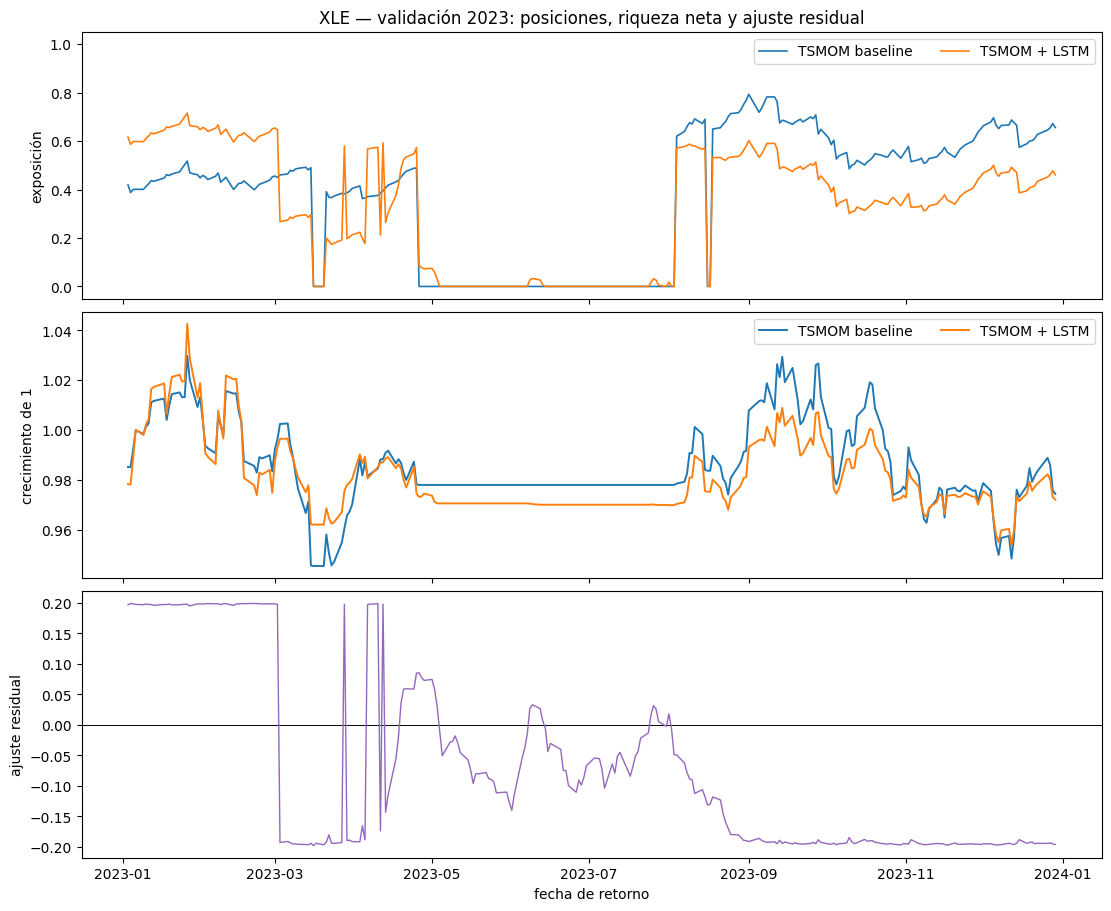

Ajuste residual medio: -6.87%; sesiones con |ajuste| > 1 pp: 97.6%.
Interpretación 2023: la red redujo la exposición media en 5.17 pp y el Sharpe neto cambió -0.053. Esta única validación no permite atribuir causalidad ni inferir alpha.


In [8]:
validation_dates = sample.loc[validation_idx, 'return_date']
validation_adjustment = learned_adjustment[validation_idx]
baseline_position = sample.loc[validation_idx, 'baseline_position'].to_numpy()
lstm_position = learned_position[validation_idx]

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, layout='constrained')
axes[0].plot(validation_dates, baseline_position, label='TSMOM baseline', lw=1.2)
axes[0].plot(validation_dates, lstm_position, label='TSMOM + LSTM', lw=1.2)
axes[0].set_ylabel('exposición')
axes[0].set_ylim(-0.05, 1.05)
axes[0].legend(ncol=2)
axes[0].set_title('XLE — validación 2023: posiciones, riqueza neta y ajuste residual')

axes[1].plot(validation_dates, baseline_eval['wealth'], label='TSMOM baseline', lw=1.4)
axes[1].plot(validation_dates, lstm_eval['wealth'], label='TSMOM + LSTM', lw=1.4)
axes[1].set_ylabel('crecimiento de 1')
axes[1].legend(ncol=2)

axes[2].axhline(0, color='black', lw=0.7)
axes[2].plot(validation_dates, validation_adjustment, color='tab:purple', lw=1.0)
axes[2].set_ylabel('ajuste residual')
axes[2].set_xlabel('fecha de retorno')
plt.show()

active_adjustment = (np.abs(validation_adjustment) > 0.01).mean()
print(f'Ajuste residual medio: {validation_adjustment.mean():.2%}; sesiones con |ajuste| > 1 pp: {active_adjustment:.1%}.')
sharpe_difference = lstm_eval['Sharpe neto'] - baseline_eval['Sharpe neto']
exposure_difference = baseline_eval['exposición media (%)'] - lstm_eval['exposición media (%)']
print(f'Interpretación 2023: la red redujo la exposición media en {exposure_difference:.2f} pp y el Sharpe neto cambió {sharpe_difference:.3f}. Esta única validación no permite atribuir causalidad ni inferir alpha.')

## <b>Conclusión</b>

- La LSTM no sustituye al baseline: sólo desplaza una exposición TSMOM ya definida y permanece en long/cash.
- La comparación de 2023 incluye el mismo coste proporcional para ambas políticas y respeta el orden de las posiciones.
- Cualquier diferencia observada resume una sola validación retrospectiva, con una arquitectura y una semilla fijadas antes de mirar los resultados.
- No permite atribuir una mejora a memoria temporal, ni inferir alpha, ni concluir viabilidad operativa: faltan una muestra no explorada, ejecución realista y análisis de robustez.